In [6]:
# !/usr/bin/env python3 
# executable - set up paths for import
import os
import sys
# to setup import paths add project root dir to sys.path (with baseVR dir in it)
sys.path.append(os.path.join(os.getcwd(), "..", ".."))
from baseVR.base_functionality import init_import_paths
init_import_paths()

# Auto-reload modules before executing code
%load_ext autoreload
%autoreload 2
# %matplotlib qt


from dashsrc.plot_components.plots import plot_unit_fr_stability
from dashsrc.plot_components.plots import plot_EnsambleEncondings
from analytics_processing import analytics
import analytics_processing.analytics_constants as C
from CustomLogger import CustomLogger as Logger
from analytics_processing.modality_loading import session_modality_from_nas
from analytics_processing.sessions_from_nas_parsing import sessionlist_fullfnames_from_args
from analytics_processing.sessions_from_nas_parsing import fullfnames2snames


from dashsrc.plot_components.plots import plot_SessionWaveforms
from dashsrc.plot_components.plots import plot_EnsembleChoiceEncoding
from dashsrc.plot_components.plot_wrappers.data_selection import group_filter_data

from dashsrc.plot_components.plots import plot_adc_bias


output_dir = "/mnt/SpatialSequenceLearning/Simon/fr_stability/"
data = {}
nas_dir = C.device_paths()[0]
Logger().init_logger(None, None, logging_level="WARNING")

import plotly.io as pio



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [ ]:
                                                        # 1 2 
# 3,4,5,6,7,8,9,10,11,12,13,14,
# animal_ids = [6]
animal_ids = [10]
# session_ids = [0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30]
# session_ids = [5,6,7,8,9,10]
# session_ids = [11,12,13,14,]
# session_ids = [15,16,17,18,19,20,21,22,23,24,25,26]
# session_ids = None
session_ids = None
paradigm_ids = [0, 1100]
# excl_session_names = ['2024-11-29_17-21_rYL006_P1100_LinearTrackStop_28min', '2025-01-21_18-49_rYL006_P1100_LinearTrackStop_30min', '2024-12-11_17-42_rYL006_P1100_LinearTrackStop_30min']
excl_session_names = None
# cols = ["session_spike_count", "session_nsamples", "cluster_id", "unit_snr", "unit_Vpp"]
cols = None
width = 700
height = 700
group_by = None

# data['SessionMetadata'] = analytics.get_analytics('SessionMetadata', mode='set',
# data['Spikes'] = analytics.get_analytics('Spikes', mode='set',
data['SpikeClusterMetadata'] = analytics.get_analytics('SpikeClusterMetadata', mode='set',
# data['SessionMetadata'] = analytics.get_analytics('SessionMetadata', mode='set',
                                                       columns = cols,
                                                       paradigm_ids=paradigm_ids,
                                                       animal_ids=animal_ids,
                                                       excl_session_names=excl_session_names,
                                                       session_ids=session_ids)
data['Spikes'] = analytics.get_analytics('Spikes', mode='set',
                                                       columns = cols,
                                                       paradigm_ids=paradigm_ids,
                                                       animal_ids=animal_ids,
                                                       excl_session_names=excl_session_names,
                                                       session_ids=session_ids)

# data['Spikes']
data['SpikeClusterMetadata'].sort_index(level=['session_id'], inplace=True)
# data['Spikes'].sort_index(level=['session_id'], inplace=True)
# data['SpikeClusterMetadata'].index.droplevel(['entry_id', 'animal_id']).drop_duplicates()
# data['SessionMetadata']

In [ ]:
data['FiringRate40msHz'] = analytics.get_analytics('FiringRate40msHz', mode='set',
                                        #  columns = cols,
                                        paradigm_ids=paradigm_ids,
                                        animal_ids=animal_ids,
                                        excl_session_names=excl_session_names,
                                        session_ids=session_ids)
data['FiringRate40msHz']


In [ ]:
data['FiringRate40msZ'] = analytics.get_analytics('FiringRate40msZ', mode='set',
                                        #  columns = cols,
                                        paradigm_ids=paradigm_ids,
                                        animal_ids=animal_ids,
                                        excl_session_names=excl_session_names,
                                        session_ids=session_ids)
data['FiringRate40msZ']

In [ ]:
# data['SpikeClusterMetadata'] = data['SpikeClusterMetadata'][data['SpikeClusterMetadata'].cluster_id<21]
# data['SpikeClusterMetadata'][['session_spike_count', 'session_nsamples', 'cluster_id']]

In [ ]:
# fig = plot_unit_fr_stability.render_plot_lineplot(data['SpikeClusterMetadata'])
fig = plot_unit_fr_stability.render_plot_heatmap(data['SpikeClusterMetadata'])
# fig = plot_unit_fr_stability.render_plot_lineplot(data['FiringRate40msHz'])
# fig = plot_unit_fr_stability.render_plot_lineplot(data['FiringRate40msZ'])
# fullfname = f'{output_dir}/unit_fr_stability.svg'
fullfname = f'{output_dir}rat10_unit_fr_spikemetadata.html'
# write html
fig.write_html(fullfname)
print(f"Saved to {fullfname}")

In [ ]:
fig = plot_SessionWaveforms.render_plot(data['SpikeClusterMetadata'], 
                                        data['SessionMetadata'], 
                                        width=1200, height=800
                                        )


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.close('all' )

plt.figure(figsize=(2,5))
# left space
plt.subplots_adjust(left=0.6)
vals = data['SpikeClusterMetadata'].unit_snr.values
vals = np.unique(vals)
print(len(vals))

x_jitter = np.random.normal(0, 0.04, size=len(vals)) + 1
mean_snr = np.mean(vals)
plt.axhline(mean_snr, color='gray', linestyle='--', label=f'Mean SNR: {mean_snr:.2f}')
plt.legend(frameon=False, loc='upper right')
plt.ylabel('Unit SNR')
plt.title('Unit SNR across all units')
# no spines
[plt.gca().spines[side].set_visible(False) for side in ['top', 'right', 'left']]
# drop duplicates (every sessionhas same snr)
plt.scatter(x_jitter, vals, alpha=.5, color='#8c6565')
plt.xlim(0.5, 1.5)
# add y axis grid
plt.gca().yaxis.grid(True, linestyle='--', alpha=0.5)
plt.ylim(0,20)

plt.show()

plt.savefig(os.path.join(output_dir, 'unit_snr_allunits.svg'), format='svg', dpi=300)

In [ ]:
# highlight_cluster = 46
sess_Vpp = data['Spikes'].reset_index()[['session_id','cluster_id','amplitude_uV']].groupby(['session_id','cluster_id']).mean()

fig = plot_unit_fr_stability.render_plot_amplitude(data['SpikeClusterMetadata'], sess_Vpp)
fullfname = f'{output_dir}/unit_fr_stability_logger_rat10.svg'
fig.write_image(fullfname, width=800, height=400, scale=1)
# execute = f"code {fullfname}"
# os.system(execute)
fig.show()

In [ ]:
# session_ids = 
# session_ids = 
session_dir_tethered = sessionlist_fullfnames_from_args(session_ids=['2025-05-09_14-58'])[0][0]
session_dir_logger = sessionlist_fullfnames_from_args(session_ids=['2025-05-09_15-51'])[0][0]

In [ ]:
mmap_data, mapping = session_modality_from_nas(session_dir_logger, 'ephys_traces')
n_samples_logger = mmap_data.shape[1]
ampl_ids_logger = mapping.amplifier_id.values

mmap_data, mapping = session_modality_from_nas(session_dir_tethered, 'ephys_traces')
n_samples_tethered = mmap_data.shape[1]
ampl_ids_tethered = mapping.amplifier_id.values


In [ ]:

# aggr_histogram, clipping_counts = plot_adc_bias.calculate_bias_histogram(
#     session_dir, 
#     n_samples=n_samples,
#     ampl_ids=ampl_ids
# )


In [ ]:
# # raw_traces = read_raw_data(os.path.dirname(logger_sess_dir), 'ephys_output.raw.h5', convert2uV=False, col_slice=slice(0, 2048))
# raw_traces_logger = read_raw_data(os.path.dirname(logger_sess_dir), 
#                            '2025-05-09_15-51_rYL010_P0000_SleepSession_164min_ephys_logger.raw.h5', 
#                            convert2uV=False, col_slice=slice(20))
# raw_traces_logger    

In [ ]:


fig = plot_adc_bias.render_bias_heatmap(aggr_histogram)
fig.show()
fig = plot_adc_bias.render_clipping_plot(clipping_counts)
fig.show()


In [ ]:


fig = plot_adc_bias.render_bias_heatmap(aggr_histogram)
# fig = plot_adc_bias.render_clipping_plot(clipping_counts)
# fig = plot_adc_bias.render_bias_heatmap(aggr_histogram_tethered)
# fig = plot_adc_bias.render_clipping_plot(clipping_counts_tethered)
fig.show()

n_samples_logger
n_samples_tethered
session_dir_tethered
session_dir_logger
ampl_ids_logger
ampl_ids_tethered


In [ ]:
n_samples_logger
n_samples_tethered
session_dir_tethered
session_dir_logger
ampl_ids_logger
ampl_ids_tethered

In [ ]:
# Calculate RMS for both sessions with 20 chunks
rms_per_channel_tethered, rms_all_chunks_tethered = plot_adc_bias.calculate_rms_noise(
    session_dir_tethered, n_samples_tethered, ampl_ids=ampl_ids_tethered, n_chunks=20
)

rms_per_channel_logger, rms_all_chunks_logger = plot_adc_bias.calculate_rms_noise(
    session_dir_logger, n_samples_logger, ampl_ids=ampl_ids_logger, n_chunks=20
)

# Plot both sessions side by side
fig = plot_adc_bias.render_rms_violin(
    rms_all_chunks_tethered, rms_all_chunks_logger,
    color1='#5A8FC6', color2='#CCCCCC',
    label1='Tethered', label2='Logger',
    title='RMS Noise: Tethered vs Logger'
)
fig.show()

In [ ]:
fig = plot_adc_bias.render_channel_stack_comparison(
    session_dir_tethered, session_dir_logger,
    n_samples_tethered, n_samples_logger,
    ampl_ids_tethered, ampl_ids_logger,
    chunk_idx=6, start_channel=560, n_channels=60
)
fig.show()

In [2]:
animal_ids = [6]

session_ids = None

paradigm_ids = [1100]


0: /mnt/SpatialSequenceLearning/RUN_rYL006/rYL006_P1100/2024-11-14_15-01_rYL006_P1100_LinearTrackStop_30min/2024-11-14_15-01_rYL006_P1100_LinearTrackStop_30min.hdf5
Skipping session /mnt/SpatialSequenceLearning/RUN_rYL006/rYL006_P1100/2024-11-14_15-01_rYL006_P1100_LinearTrackStop_30min/2024-11-14_15-01_rYL006_P1100_LinearTrackStop_30min.hdf5 due to missing ephys_traces modality.
1: /mnt/SpatialSequenceLearning/RUN_rYL006/rYL006_P1100/2024-11-14_16-40_rYL006_P1100_LinearTrackStop_21min/2024-11-14_16-40_rYL006_P1100_LinearTrackStop_21min.hdf5
n_samples: 25759600, ampl_ids: [ 939  115  835   75   45  871   11  167  983  791  159   35  731  495
  131  651  399  727  971  219  595  851  395  739 1023  263    7  887
  599  163  283  667  243   83  843  679  203  215  987  963  175   69
  823  451   31  867  647  491 1003  507  143   85  523  135  187  815
  615  335   59  659  607  355  183  695  687  275  779   67  151  423
  799  671  291  127  719  319  863  723  995  735  455  199  787  

/home/vrmaster/Projects/VirtualReality/ephysVR/mea1k_modules/mea1k_raw_preproc.py:95: RuntimeWarning: overflow encountered in multiply
  np.multiply(data, 1000, out=data)
2026-04-15 11:12:44,151|WARNING|757598|mea1k_raw_preproc|_ADC2voltage
	Overflow detected in data, casting to <class 'numpy.int16'>...
2026-04-15 11:12:44,151|WARNING|757598|mea1k_raw_preproc|_ADC2voltage
	Overflow detected in data, casting to <class 'numpy.int16'>...
/home/vrmaster/Projects/VirtualReality/ephysVR/mea1k_modules/mea1k_raw_preproc.py:100: RuntimeWarning: invalid value encountered in cast
  data = data.astype(dtype)


Processed chunk 1/10

2026-04-15 11:12:45,145|WARNING|757598|mea1k_raw_preproc|_ADC2voltage
	Overflow detected in data, casting to <class 'numpy.int16'>...
2026-04-15 11:12:45,145|WARNING|757598|mea1k_raw_preproc|_ADC2voltage
	Overflow detected in data, casting to <class 'numpy.int16'>...


Processed chunk 2/10

...

Processed chunk 8/10

/home/vrmaster/Projects/VirtualReality/ephysVR/mea1k_modules/mea1k_raw_preproc.py:169: RuntimeWarning: overflow encountered in cast
  raw_data = np.array(file[data_key][row_slice, col_slice], dtype=dtype)
2026-04-15 11:14:59,556|WARNING|757598|mea1k_raw_preproc|_ADC2voltage
	Overflow detected in data, casting to <class 'numpy.int16'>...
2026-04-15 11:14:59,556|WARNING|757598|mea1k_raw_preproc|_ADC2voltage
	Overflow detected in data, casting to <class 'numpy.int16'>...


Processed chunk 9/10

2026-04-15 11:15:00,497|WARNING|757598|mea1k_raw_preproc|_ADC2voltage
	Overflow detected in data, casting to <class 'numpy.int16'>...
2026-04-15 11:15:00,497|WARNING|757598|mea1k_raw_preproc|_ADC2voltage
	Overflow detected in data, casting to <class 'numpy.int16'>...


Processed chunk 10/10
Done!
✅ RMS must be combined as a quadratic (power) mean
28: /mnt/SpatialSequenceLearning/RUN_rYL006/rYL006_P1100/2025-01-24_19-37_rYL006_P1100_LinearTrackStop_40min/2025-01-24_19-37_rYL006_P1100_LinearTrackStop_40min.hdf5
n_samples: 48917200, ampl_ids: [ 939  115  835   75   45  871   11  167  983  791  159   35  731  495
  131  651  399  727  971  219  595  851  395  739 1023  263    7  887
  599  163  283  667  243   83  843  679  203  215  987  963  175   69
  823  451   31  867  647  491 1003  507  143   85  523  135  187  815
  615  335   59  659  607  355  183  695  687  275  779   67  151  423
  799  671  291  127  719  319  863  723  995  735  455  199  787  427
  231  827   47  407   77 1015  551  403  467  655  571  763  463  559
  295  211  707  299  755  531  603  251  879  267  555  171  795  543
  623   79  683  271  287  155  775  579  483  895  391  591  415  743
  611  431  103  635  471  703  639  111  419  631  803  759  539  663
  563  535  19

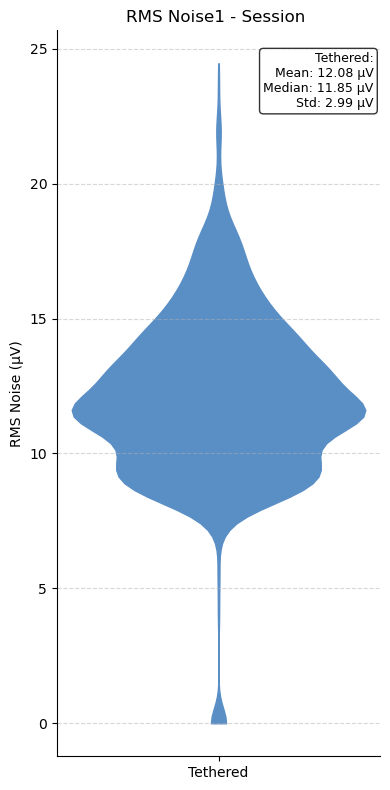

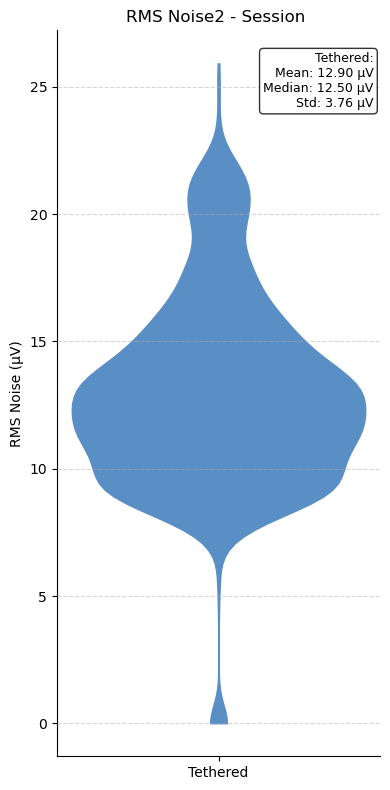

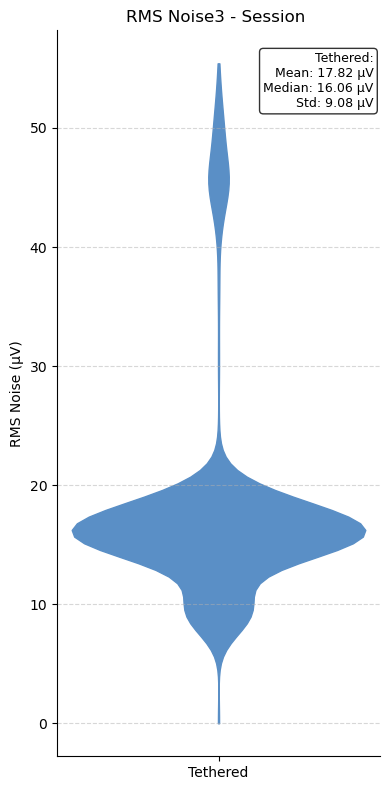

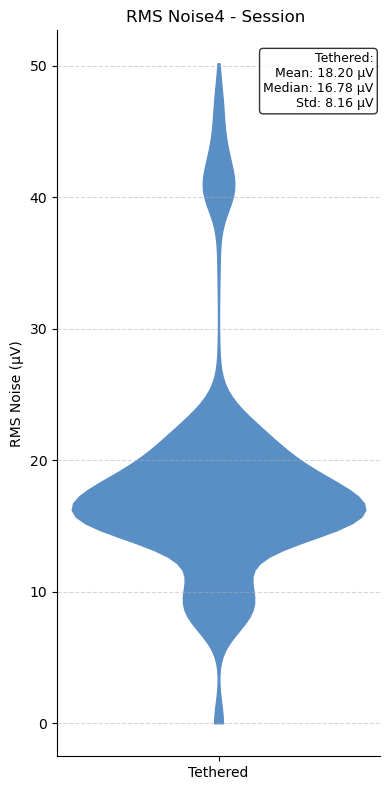

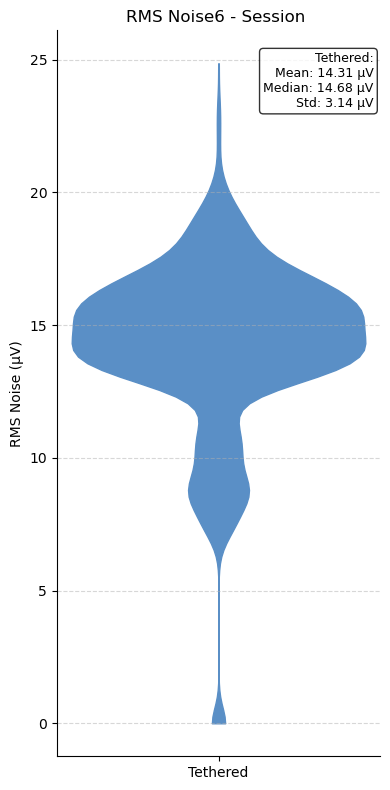

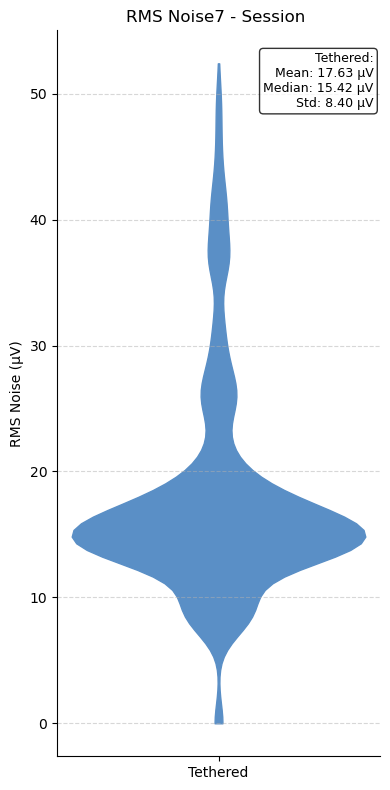

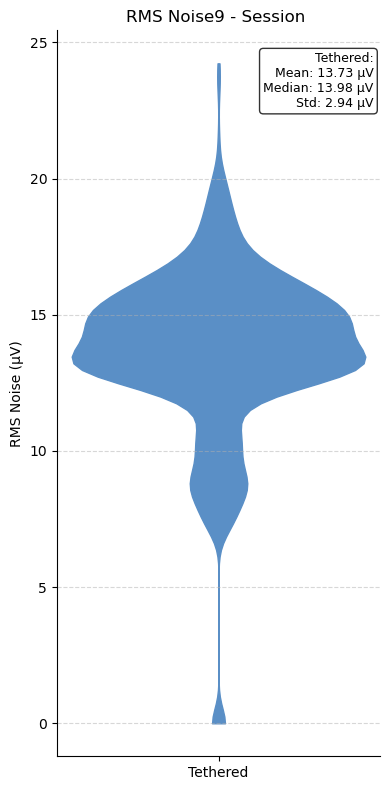

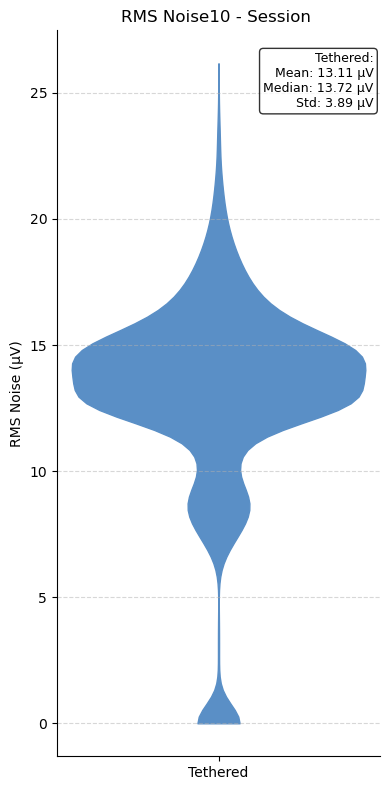

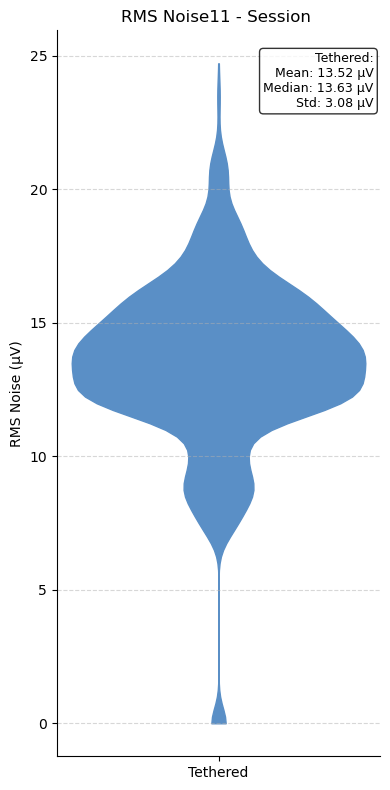

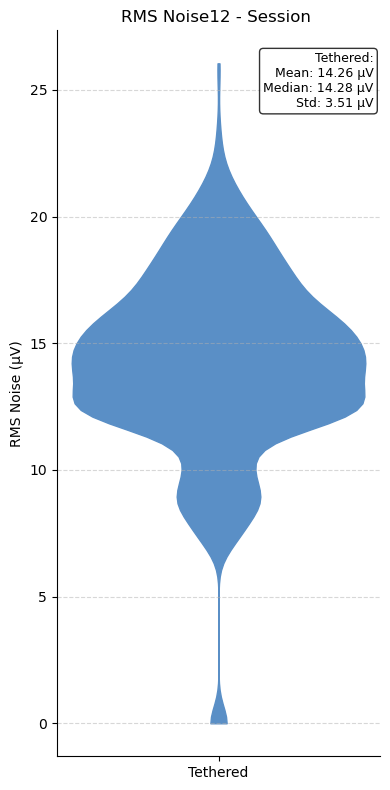

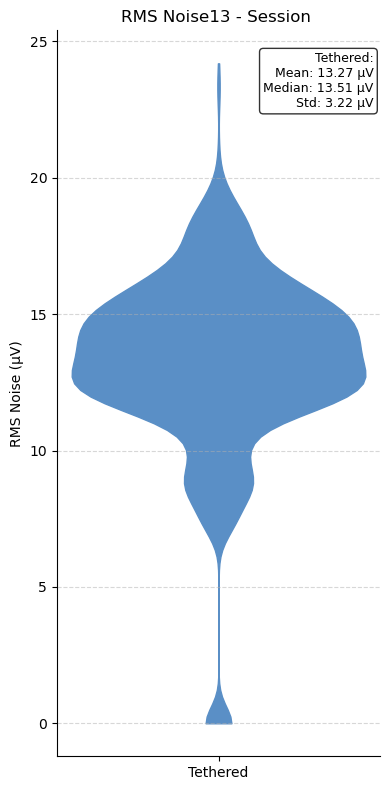

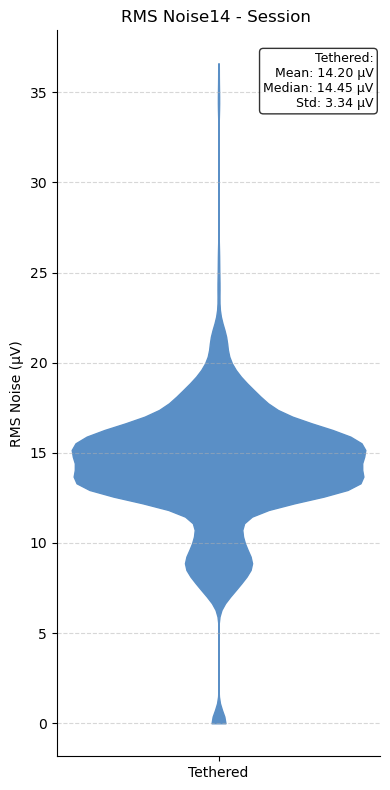

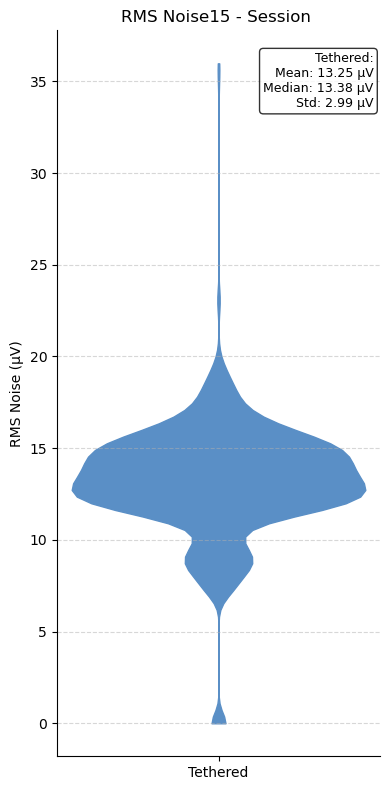

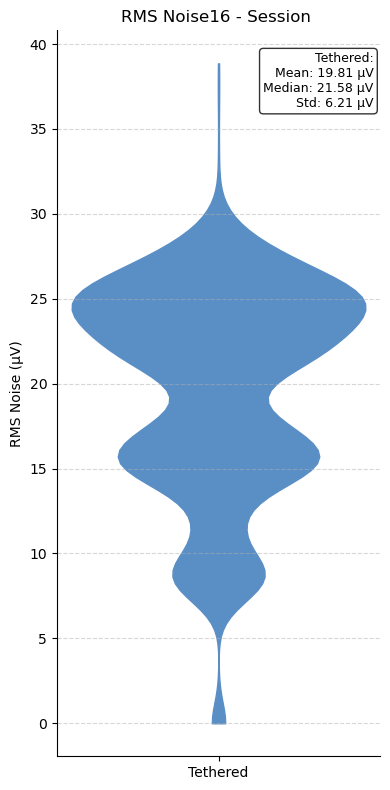

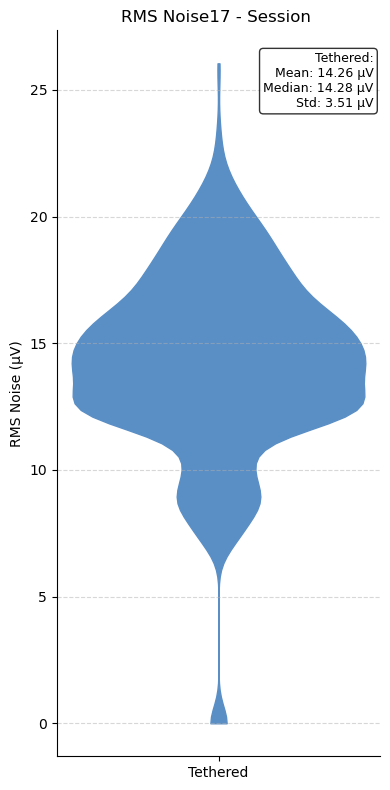

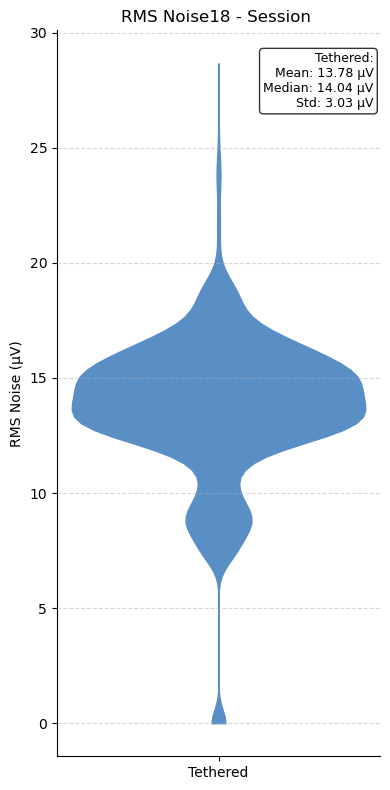

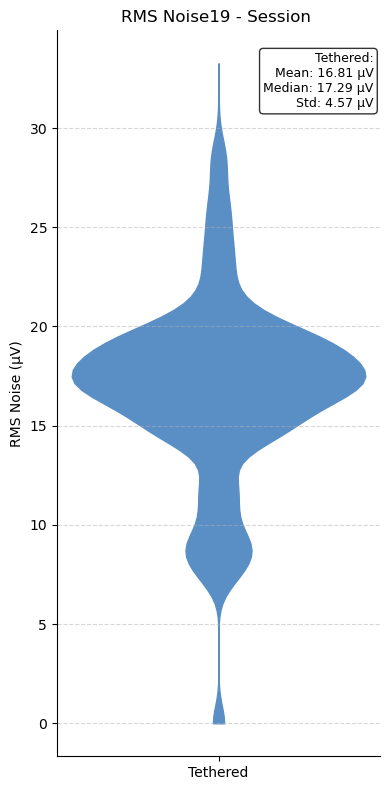

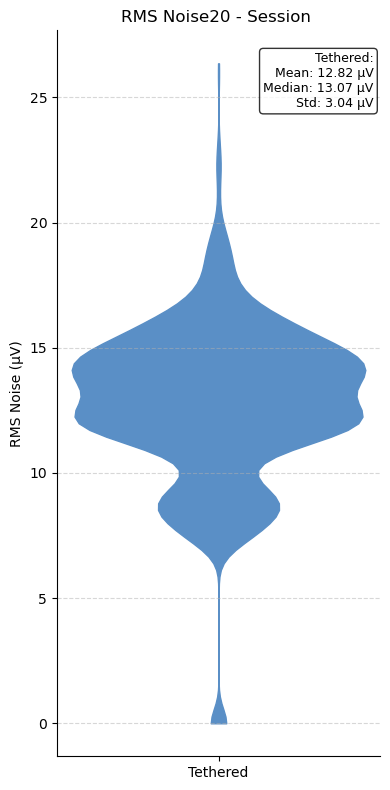

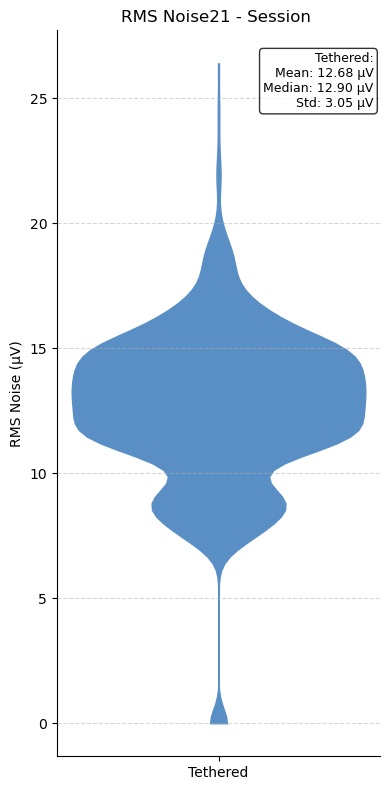

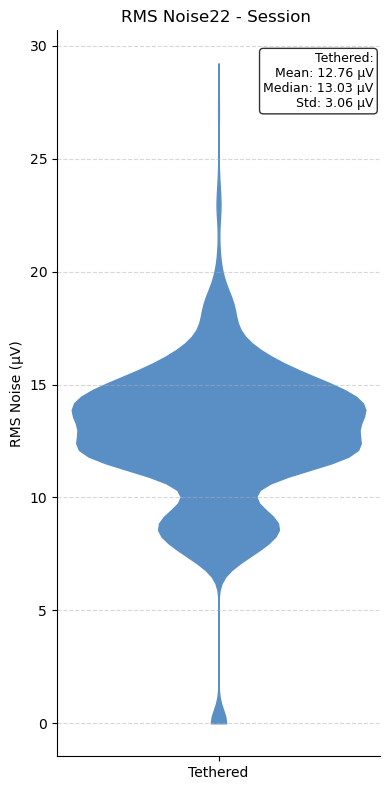

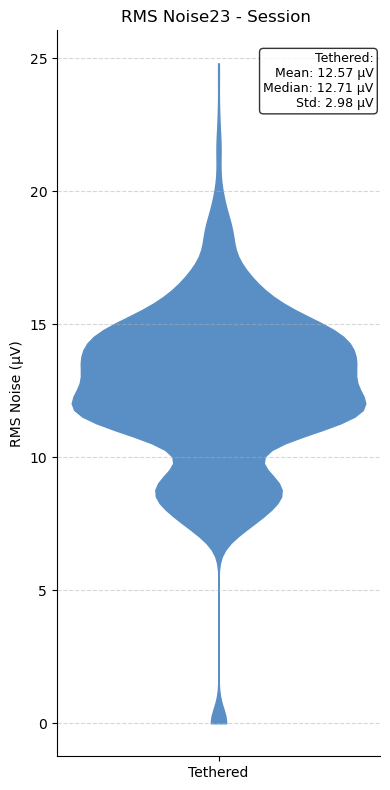

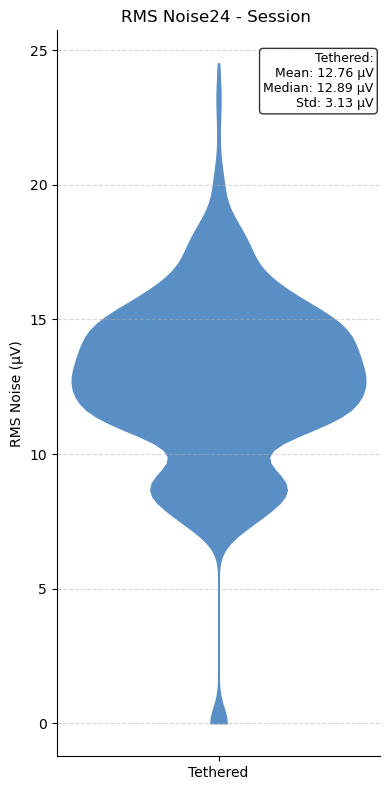

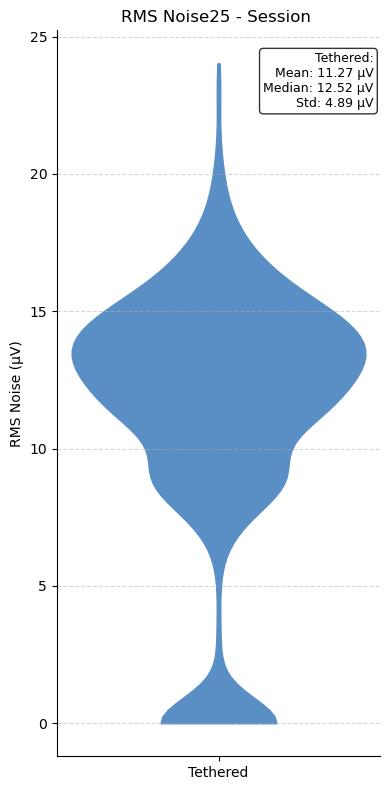

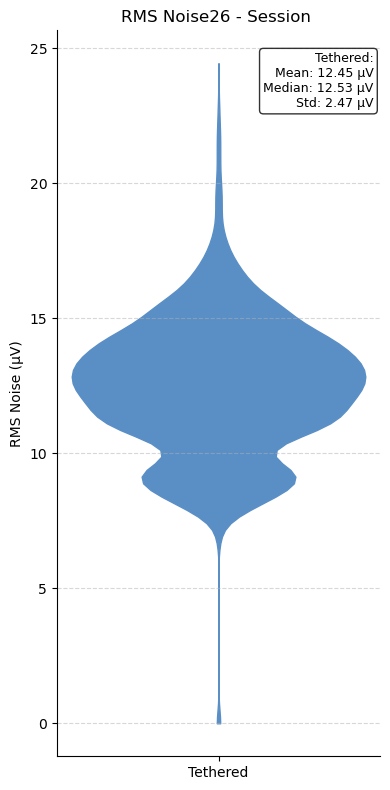

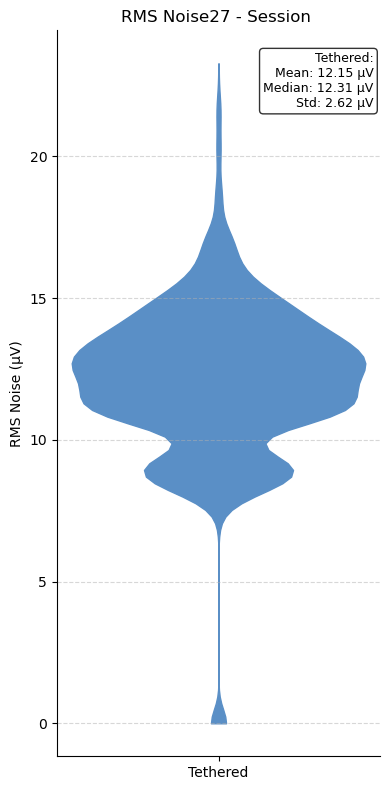

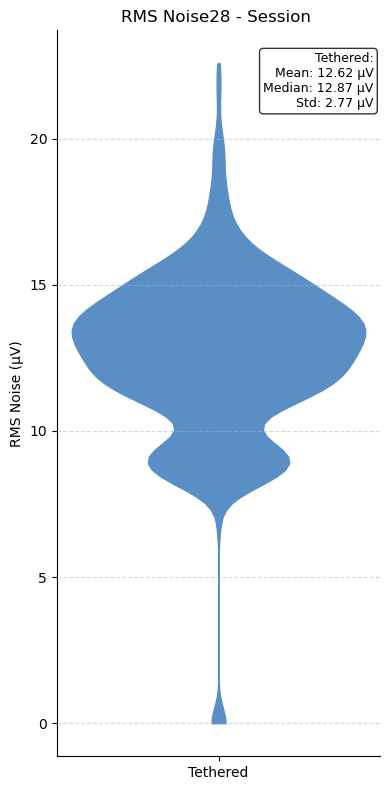

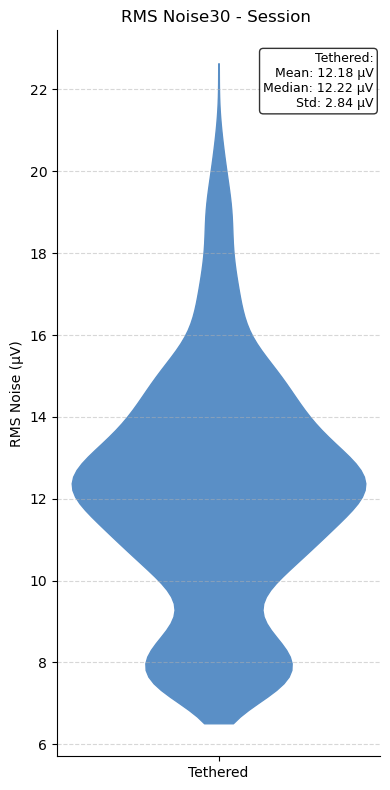

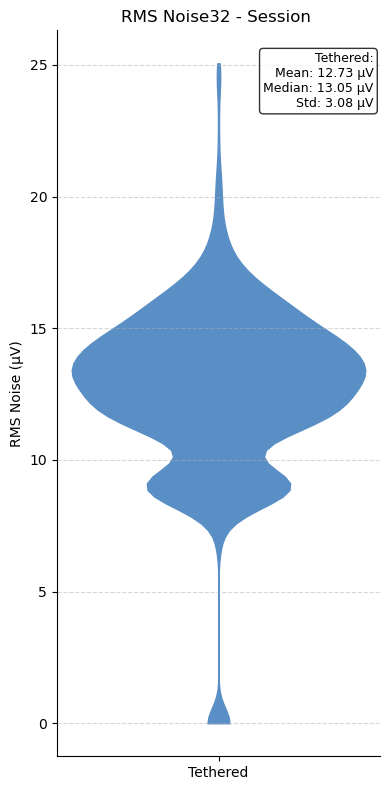

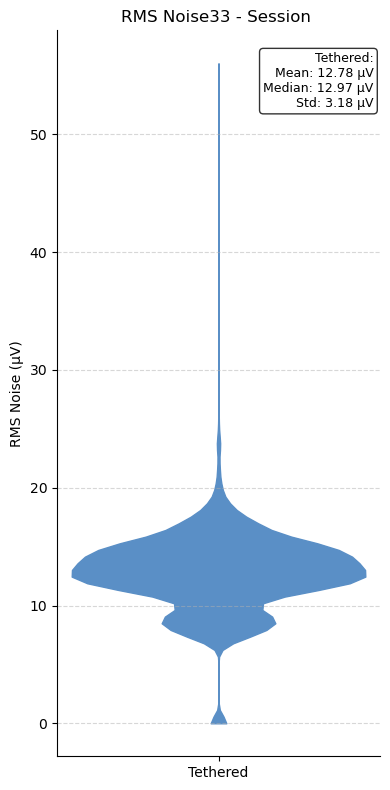

In [10]:
session_dirs = sessionlist_fullfnames_from_args(animal_ids=animal_ids, session_ids=session_ids, 
                                               paradigm_ids=paradigm_ids)[0]

for i in range(len(session_dirs)):
    print(f"{i}: {session_dirs[i]}")
    
    session_dir = session_dirs[i]
    mmap_data, mapping = session_modality_from_nas(session_dir, 'ephys_traces')
    if mmap_data is None or mapping is None:
        print(f"Skipping session {session_dir} due to missing ephys_traces modality.")
        continue
    n_samples = mmap_data.shape[1]
    ampl_ids = mapping.amplifier_id.values
    print(f"n_samples: {n_samples}, ampl_ids: {ampl_ids}")


    # Calculate RMS for both sessions with 20 chunks
    rms_per_channel, rms_all_chunks = plot_adc_bias.calculate_rms_noise(
        session_dir, n_samples, ampl_ids=ampl_ids, n_chunks=10
    )

    
    # Plot both sessions side by side
    fig = plot_adc_bias.render_rms_violin(
        rms_all_chunks, 
        color1='#5A8FC6', 
        label1='Tethered', 
        title='RMS Noise' + str(i) + " - Session "
    )
    fig.show()

    # fig = plot_adc_bias.render_channel_stack_comparison(
    #     session_dir, session_dir, 
    #     n_samples,n_samples,
    #     ampl_ids,ampl_ids,
    #     chunk_idx=6, start_channel=1, n_channels=30
    # )
    # fig.show()